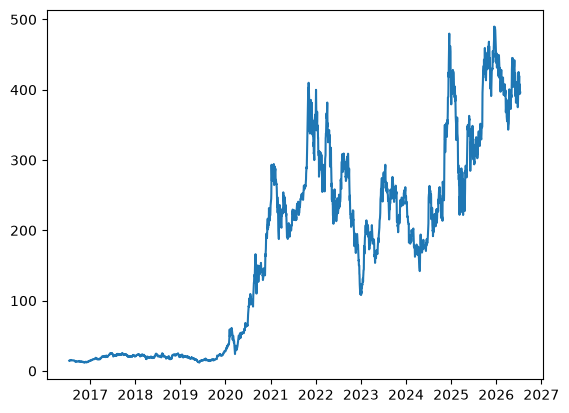

In [36]:

import pandas as pd 
import datetime
import matplotlib.pyplot as plt 

# Import data frame: 
df = pd.read_csv(r'TSLA.csv')
df = df[['Date', 'Close/Last']]

# This will print out <class 'str'>, meaning we need to convert the entire date column to Date types. 
#print(type(df['Date'][0])) 
#print(type(df['Close/Last'][0]))

def string_to_datetime(s):
    split = s.split('/')
    month, day, year = int(split[0]), int(split[1]), int(split[2])
    return datetime.datetime(year, month, day)
    
def string_to_float(s):
    split = s.replace("$","")
    return float(split)

df['Date'] = df['Date'].apply(string_to_datetime)
df['Close/Last'] = df['Close/Last'].apply(string_to_float)
df.index = df.pop('Date') # Making the date column be the index column. 
df = df.sort_index()

plt.plot(df.index, df['Close/Last'])



In [37]:
import numpy as np  
# Gets three previous values, then what it actually is of all states between a start and end date. 
# Change n to change the amount of previous values retrieved. 
def df_to_windowed_df(dataframe, first_date, last_date, n=3):
  first_date = string_to_datetime(first_date)
  last_date  = string_to_datetime(last_date)
  print(str(first_date))
  print(str(last_date))

  target_date = first_date
  
  dates = []
  X, Y = [], []

  last_time = False
  while True:
    df_subset = dataframe.loc[:target_date].tail(n+1)
    #print(str(df_subset))
    
    if len(df_subset) != n+1:
      print(f'Error: Window of size {n} is too large for date {target_date}')
      return

    values = df_subset['Close/Last'].to_numpy()
    x, y = values[:-1], values[-1]

    dates.append(target_date)
    X.append(x)
    Y.append(y)

    next_week = dataframe.loc[target_date:target_date+datetime.timedelta(days=7)]
    if next_week.empty: 
      print("Next Week doesn't exist!")
      i=1
      while next_week.empty == True and i != 4: 
        print(f"there's no day {i} days after: {str(target_date)}")
        print(f"We're currently looking for: {target_date+datetime.timedelta(days=7+i)}")
        next_week = dataframe.loc[target_date:target_date+datetime.timedelta(days=7+i)]
        # print(str(next_week))
        i+=1
        if target_date+datetime.timedelta(days=7+i) == last_date: 
          last_time = True 
         
    #print(str(next_week))
    next_datetime_str = str(next_week.head(2).tail(1).index.values[0])
    #print(str(next_datetime_str))
    next_date_str = next_datetime_str.split('T')[0]
    year_month_day = next_date_str.split('-')
    year, month, day = year_month_day
    next_date = datetime.datetime(day=int(day), month=int(month), year=int(year))
    
    if last_time:
      break
    
    target_date = next_date
    # print(f"----------------{str(next_date)}")
    # print(str(last_date))

    # Found out that it went on and on because the start date I had was skipped past typically, causing it to run forever. 
    if target_date == last_date or target_date > last_date: 
      last_time = True
    
  ret_df = pd.DataFrame({})
  ret_df['Target Date'] = dates
  
  X = np.array(X)
  for i in range(0, n):
    X[:, i]
    ret_df[f'Target-{n-i}'] = X[:, i]
  
  ret_df['Target'] = Y

  return ret_df


2021-03-25 00:00:00
2025-03-23 00:00:00


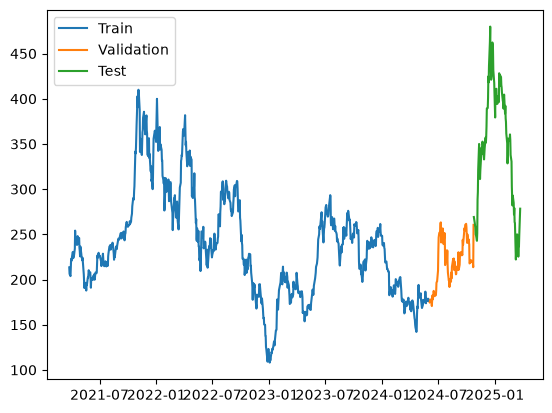

In [38]:
def windowed_df_to_date_X_y(df_to_windowed_df): 
    # X is going to be the matrix consisted of the three previous values 
    # Y is going to be the singular true value 
    df_as_np = df_to_windowed_df.to_numpy()
    dates = df_as_np[:,0]

    middle_matrix = df_as_np[:, 1:-1] # we want to get the only three 
    X = middle_matrix.reshape((len(dates), middle_matrix.shape[1], 1)) 
    Y = df_as_np[:, -1]

    return dates, X.astype(np.float32), Y.astype(np.float32)

# Start day second time around: '2021-03-25'
windowed_df = df_to_windowed_df(df, '3/25/2021', '3/23/2025', n=3)

dates, X, y = windowed_df_to_date_X_y(windowed_df) # we must get windowed soon 
q_80 = int(len(dates) * 0.8)
q_90 = int(len(dates) * 0.9)

dates_train, X_train, y_train = dates[:q_80], X[:q_80], y [:q_80]

dates_val, X_val, y_val = dates[q_80:q_90], X[q_80:q_90], y[q_80:q_90]
dates_test, X_test, y_test = dates[q_90:], X[q_90:], y[q_90:]

plt.plot(dates_train, y_train)
plt.plot(dates_val, y_val)
plt.plot(dates_test, y_test)

plt.legend(['Train', 'Validation', 'Test'])



In [39]:
from tensorflow.keras.models import Sequential 
from tensorflow.keras.optimizers import Adam 
from tensorflow.keras import layers 

# We'll make a Sequential Model with many layers 
# 3 (3 days in the past), only need univariate forecasting (Univariate because we're just using the closing price)
# 64 Neurons (not too many) for the LSTM. The bigger the number, the more complicated and the more prone it is to over fitting.

# Sequential means we're stacking the layers provided in order, feeding each one's output into the next one 
# LSTM (Long Short Term Memory): We're carrying a runnning internal memory foward,. It uses learned gates to decide what to keep/forget/update. 64 is Internal Memory. 
# Outputs a single 64 number summary vector. 

# Dense: Fully connected. Each one of the 32 neurons looks at all 64 numbers from the LSTM and combines them with its own learned weights. 
# relu : Rectified linear unit: the function done after the combination and zeroes out any negative values. 

# Two Denses because an extra pass to nonlinearly recombine the summary before the final number. 
# Outputs the raw weighted sum with no "squashing" 
model = Sequential([layers.Input((3, 1)), 
                    layers.LSTM(64), # Not messing with activation methods of LSTM
                    layers.Dense(32, activation='relu'), # No idea what Dense, Activation or relu means. 
                    layers.Dense(32, activation='relu'), 
                    layers.Dense(1)]) # Default activation is linear

# Mean Squared Error is what the model is minimizing 
# Adam adjusts how big a step to take when updating the weights each round.
# 'mean_absolute_error' gets reported 
model.compile(loss='mse', 
              optimizer=Adam(learning_rate=0.001), # Learning rate is something we mess around with. 
              metrics = ['mean_absolute_error']) # How much we're off by on average 

# 100 full passes. 
model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100) # 100 runs in the data set. 
# We want to care about the val_mean_absolute_error. If it doesn't change too much (it hovers), then we can cancel and it'll save. 



Epoch 1/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 59525.0898 - mean_absolute_error: 237.0826 - val_loss: 48169.3398 - val_mean_absolute_error: 218.0623
Epoch 2/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 57602.5898 - mean_absolute_error: 233.0015 - val_loss: 45040.2344 - val_mean_absolute_error: 210.7614
Epoch 3/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 52245.3203 - mean_absolute_error: 221.0890 - val_loss: 38015.8086 - val_mean_absolute_error: 193.3791
Epoch 4/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 41527.9844 - mean_absolute_error: 194.8505 - val_loss: 23470.6074 - val_mean_absolute_error: 151.1078
Epoch 5/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 22531.1758 - mean_absolute_error: 136.5283 - val_loss: 6290.9746 - val_mean_absolute_error: 75.2145
Epoch 6/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 6753.1807 - mean_absolute_error: 64.4631 - val_loss: 615.9710 - val_mean_absolute_error: 20.1857
Epoch 7/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


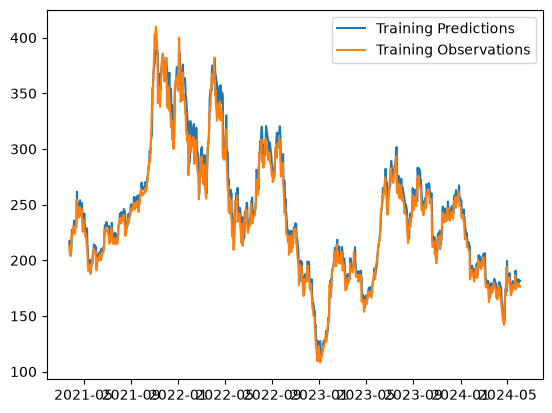

In [40]:
train_predictions=model.predict(X_train).flatten() # Gives us the predicted on the train. 

plt.plot(dates_train, train_predictions)
plt.plot(dates_train, y_train)
plt.legend(['Training Predictions', 'Training Observations'])

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


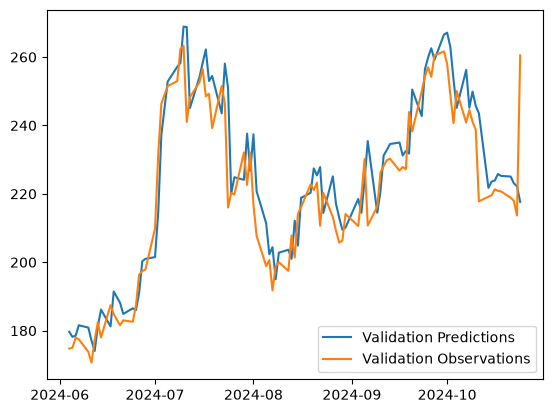

In [41]:
val_predictions=model.predict(X_val).flatten() # Gives us the predicted on the validation data . 

plt.plot(dates_val, val_predictions)
plt.plot(dates_val, y_val)
plt.legend(['Validation Predictions', 'Validation Observations'])

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


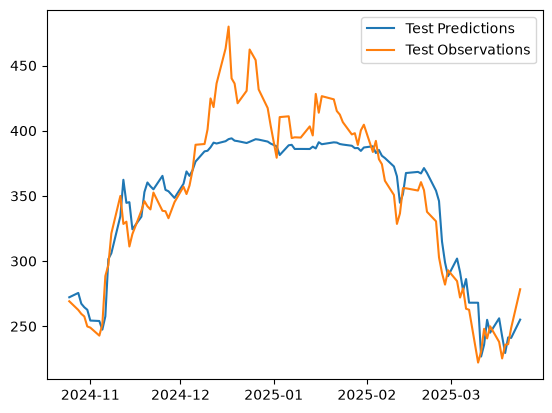

In [42]:
test_predictions=model.predict(X_test).flatten() # Gives us the predicted on the validation data . 

plt.plot(dates_test, test_predictions)
plt.plot(dates_test, y_test)
plt.legend(['Test Predictions', 'Test Observations'])

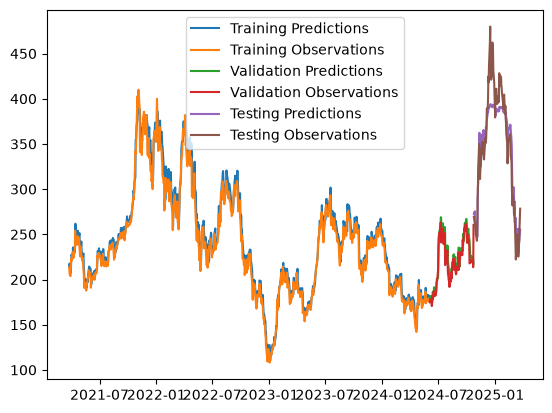

In [43]:
plt.plot(dates_train, train_predictions)
plt.plot(dates_train, y_train)
plt.plot(dates_val, val_predictions)
plt.plot(dates_val, y_val)
plt.plot(dates_test, test_predictions)
plt.plot(dates_test, y_test)
plt.legend(['Training Predictions', 
            'Training Observations',
            'Validation Predictions', 
            'Validation Observations',
            'Testing Predictions', 
            'Testing Observations'])

In [44]:
from copy import deepcopy 

recursive_predictions = []
recursive_dates = np.concatenate([dates_val, dates_test])

for target_date in recursive_dates: 
    last_window = deepcopy(X_train[-1]) # the last window that we have access to 
    next_prediction = model.predict(np.array([last_window])).flatten() 
    recursive_predictions.append(next_prediction)
    last_window[-1] = next_prediction


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━

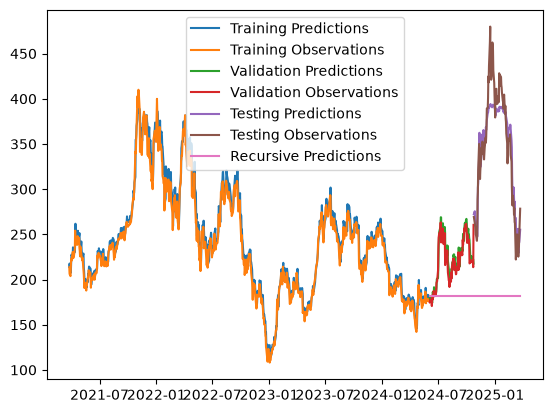

In [45]:
plt.plot(dates_train, train_predictions)
plt.plot(dates_train, y_train)
plt.plot(dates_val, val_predictions)
plt.plot(dates_val, y_val)
plt.plot(dates_test, test_predictions)
plt.plot(dates_test, y_test)
plt.plot(recursive_dates, recursive_predictions)
plt.legend(['Training Predictions', 
            'Training Observations',
            'Validation Predictions', 
            'Validation Observations',
            'Testing Predictions', 
            'Testing Observations',
            'Recursive Predictions'])